# IPSD — Minggu 6: Regresi & Klasifikasi: Linear/Logistic Regression

**Mata Kuliah:** Infrastruktur dan Platform untuk Sains Data  
**Sub-CLO:** Sub-CLO-09-4-1  
**AI Level:** L2  

**AI Level 2 — AI-Assisted Idea Generation and Structuring.** AI boleh digunakan untuk brainstorming, decomposition, alternatif struktur/pipeline, dan pertanyaan klarifikasi. Jawaban akhir, kode akhir, keputusan, dan interpretasi harus dibuat mahasiswa. Simpan prompt log.

## Capaian Praktikum
- Membedakan masalah regresi dan klasifikasi.
- Mengimplementasikan Linear Regression dan Logistic Regression.
- Memilih metrik evaluasi sesuai jenis masalah.

**Dataset:** Diabetes (regresi) dan Breast Cancer (klasifikasi) dari scikit-learn.

## Alur Praktikum
- 1. Split train-test.
- 2. Train Linear Regression dan ukur MAE/RMSE/R².
- 3. Train Logistic Regression dan ukur accuracy/precision/recall/F1.
- 4. Bandingkan kesalahan prediksi dan interpretasikan metrik.

In [1]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_diabetes, load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, accuracy_score, classification_report

# REGRESI
d = load_diabetes(as_frame=True)
X_train, X_test, y_train, y_test = train_test_split(d.data, d.target, test_size=0.2, random_state=42)
reg = LinearRegression().fit(X_train, y_train)
pred = reg.predict(X_test)
print('MAE', mean_absolute_error(y_test, pred))
print('RMSE', mean_squared_error(y_test, pred)**0.5)
print('R2', r2_score(y_test, pred))

# KLASIFIKASI
c = load_breast_cancer(as_frame=True)
X_train, X_test, y_train, y_test = train_test_split(c.data, c.target, test_size=0.2, stratify=c.target, random_state=42)
clf = LogisticRegression(max_iter=5000).fit(X_train, y_train)
pred = clf.predict(X_test)
print('Accuracy', accuracy_score(y_test, pred))
print(classification_report(y_test, pred))

MAE 42.79409467959994
RMSE 53.85344583676592
R2 0.4526027629719196
Accuracy 0.9649122807017544
              precision    recall  f1-score   support

           0       0.97      0.93      0.95        42
           1       0.96      0.99      0.97        72

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



## Membaca hasil awal

Sebelum lanjut ke latihan, saya cek dulu hasil di atas lebih teliti. Angka MAE/RMSE/accuracy saja belum cukup kalau tidak ada pembandingnya, jadi di sel berikut saya tambah model "tebak asal" (baseline) dan visualisasi sederhana.

Rata-rata target data uji : 145.8
Baseline  -> MAE 64.01 | RMSE 73.22 | R2 -0.012
LinearReg -> MAE 42.79 | RMSE 53.85 | R2 0.453

Kelas target: {'malignant': 0, 'benign': 1}
Baseline (selalu tebak 'benign') accuracy: 0.632
LogisticReg accuracy                     : 0.965

Confusion matrix:
                prediksi malignant  prediksi benign
asli malignant                  39                3
asli benign                      1               71


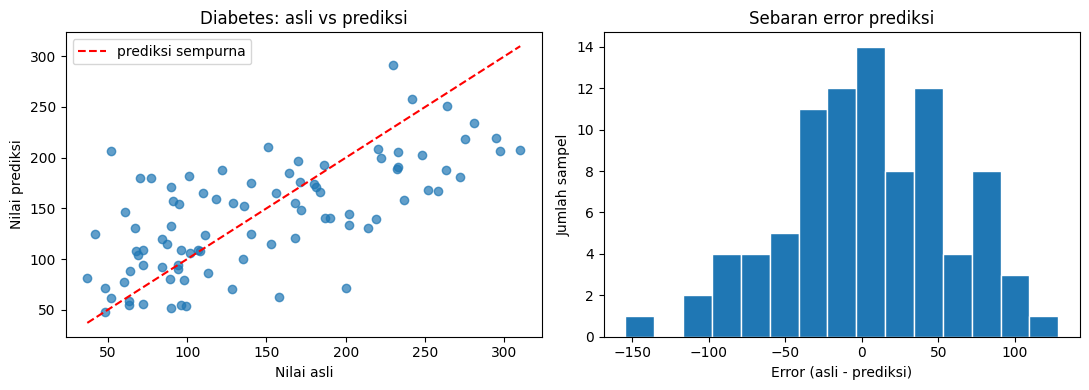

In [2]:
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score
import matplotlib.pyplot as plt

# ---------- REGRESI (diabetes) ----------
# split ulang dengan nama variabel terpisah supaya tidak tertimpa data klasifikasi
Xr_train, Xr_test, yr_train, yr_test = train_test_split(d.data, d.target, test_size=0.2, random_state=42)
reg = LinearRegression().fit(Xr_train, yr_train)
pred_reg = reg.predict(Xr_test)

# baseline: selalu menebak rata-rata target training
base_reg = DummyRegressor(strategy="mean").fit(Xr_train, yr_train)
pred_base_reg = base_reg.predict(Xr_test)

print("Rata-rata target data uji :", round(yr_test.mean(), 1))
print("Baseline  -> MAE %.2f | RMSE %.2f | R2 %.3f" % (
    mean_absolute_error(yr_test, pred_base_reg), mean_squared_error(yr_test, pred_base_reg)**0.5, r2_score(yr_test, pred_base_reg)))
print("LinearReg -> MAE %.2f | RMSE %.2f | R2 %.3f" % (
    mean_absolute_error(yr_test, pred_reg), mean_squared_error(yr_test, pred_reg)**0.5, r2_score(yr_test, pred_reg)))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(yr_test, pred_reg, alpha=0.7)
lim = [yr_test.min(), yr_test.max()]
ax[0].plot(lim, lim, "r--", label="prediksi sempurna")
ax[0].set_xlabel("Nilai asli"); ax[0].set_ylabel("Nilai prediksi")
ax[0].set_title("Diabetes: asli vs prediksi"); ax[0].legend()
ax[1].hist(yr_test - pred_reg, bins=15, edgecolor="white")
ax[1].set_xlabel("Error (asli - prediksi)"); ax[1].set_ylabel("Jumlah sampel")
ax[1].set_title("Sebaran error prediksi")
plt.tight_layout(); plt.show()

# ---------- KLASIFIKASI (breast cancer) ----------
Xc_train, Xc_test, yc_train, yc_test = train_test_split(c.data, c.target, test_size=0.2, stratify=c.target, random_state=42)
clf = LogisticRegression(max_iter=5000).fit(Xc_train, yc_train)
pred_clf = clf.predict(Xc_test)

base_clf = DummyClassifier(strategy="most_frequent").fit(Xc_train, yc_train)
print("\nKelas target:", {str(n): i for i, n in enumerate(c.target_names)})
print("Baseline (selalu tebak 'benign') accuracy: %.3f" % accuracy_score(yc_test, base_clf.predict(Xc_test)))
print("LogisticReg accuracy                     : %.3f" % accuracy_score(yc_test, pred_clf))

cm = pd.DataFrame(confusion_matrix(yc_test, pred_clf),
                  index=["asli malignant", "asli benign"], columns=["prediksi malignant", "prediksi benign"])
print("\nConfusion matrix:")
print(cm)

### Interpretasi hasil awal

**Regresi (Diabetes)**
- MAE sekitar 42,8 artinya rata-rata prediksi meleset sekitar 43 poin dari nilai asli. Rata-rata target di data uji sekitar 145,8, jadi meleset 43 poin itu lumayan besar (kira-kira 30% dari rata-ratanya).
- RMSE (53,9) lebih besar dari MAE karena error dikuadratkan dulu. Selisih RMSE dan MAE yang cukup lebar menandakan ada beberapa sampel yang meleset jauh.
- R² = 0,45 artinya model baru menjelaskan sekitar 45% variasi target. Sisanya belum tertangkap, bisa karena hubungan datanya tidak sepenuhnya linear atau ada faktor lain yang tidak ada di dataset.
- Dibanding baseline (tebak rata-rata, MAE sekitar 64 dan RMSE sekitar 73), model linear memang lebih baik, tapi belum bisa dibilang bagus. Di grafik juga kelihatan titiknya menyebar cukup lebar dari garis merah.

**Klasifikasi (Breast Cancer)**
- Accuracy 96,5% (110 dari 114 sampel benar). Baseline yang selalu menebak "benign" saja sudah dapat 63,2%.
- Perlu hati-hati dengan label: di dataset ini **0 = malignant (ganas)** dan **1 = benign (jinak)**. Jadi recall kelas 0 = 0,93 artinya dari 42 pasien yang benar-benar ganas, 39 terdeteksi dan 3 lolos diprediksi jinak.
- Kesalahan 3 kasus itu yang paling berbahaya, karena pasien ganas dianggap jinak (false negative). Sebaliknya, 1 kasus jinak yang diprediksi ganas "cuma" menyebabkan pemeriksaan lanjutan. Jadi di kasus ini recall untuk kelas malignant lebih penting daripada accuracy keseluruhan.

## Latihan Terstruktur
- Jelaskan mengapa accuracy tidak cocok untuk regresi.
- Ubah satu parameter/model setting dan bandingkan hasil.
- Buat tabel perbandingan dua problem dan metriknya.

### Latihan 1. Kenapa accuracy tidak cocok untuk regresi?

Accuracy itu menghitung berapa persen prediksi yang **persis sama** dengan label asli (benar atau salah, tidak ada setengah benar). Itu masuk akal untuk klasifikasi karena labelnya kategori terbatas (0 atau 1), jadi prediksi memang cuma bisa tepat atau meleset.

Di regresi, targetnya angka kontinu. Masalahnya ada dua:
1. Hampir mustahil prediksi persis sama dengan nilai asli sampai desimalnya. Hasilnya, accuracy hampir selalu mendekati 0% walaupun modelnya sebenarnya lumayan.
2. Accuracy tidak melihat **seberapa jauh** melesetnya. Prediksi 218 untuk nilai asli 219 dan prediksi 50 untuk nilai asli 219 sama-sama dihitung "salah", padahal yang pertama jelas jauh lebih baik.

Makanya regresi pakai metrik yang mengukur besar selisih: MAE, RMSE, dan R². Buktinya saya coba di sel bawah.

In [3]:
# coba paksa pakai accuracy di regresi: prediksi dibulatkan ke bilangan bulat dulu
y_asli = yr_test.round().astype(int)
y_prediksi = pred_reg.round().astype(int)
print("Accuracy (dipaksa) pada regresi:", round(accuracy_score(y_asli, y_prediksi), 3))

# lihat beberapa sampel, dan seberapa jauh melesetnya
contoh = pd.DataFrame({"asli": y_asli.values, "prediksi": y_prediksi})
contoh["selisih"] = (contoh["asli"] - contoh["prediksi"]).abs()
print()
print(contoh.head(8).to_string(index=False))

# dua prediksi yang sama-sama "salah" tapi kualitasnya beda jauh
print("\nContoh buatan: nilai asli 219, tebakan A = 218, tebakan B = 50")
print("accuracy tebakan A :", accuracy_score([219], [218]))
print("accuracy tebakan B :", accuracy_score([219], [50]))
print("MAE tebakan A      :", mean_absolute_error([219], [218]))
print("MAE tebakan B      :", mean_absolute_error([219], [50]))

Accuracy (dipaksa) pada regresi: 0.034

 asli  prediksi  selisih
  219       140       79
   70       180      110
  202       134       68
  230       291       61
  111       124       13
   84        92        8
  242       258       16
  272       181       91

Contoh buatan: nilai asli 219, tebakan A = 218, tebakan B = 50
accuracy tebakan A : 0.0
accuracy tebakan B : 0.0
MAE tebakan A      : 1.0
MAE tebakan B      : 169.0


### Latihan 2. Ubah satu setting model lalu bandingkan

Saya coba satu perubahan untuk tiap problem:

- Regresi: ganti `LinearRegression` dengan `Ridge` dan ubah nilai `alpha` (makin besar, koefisien makin ditekan supaya tidak terlalu liar).
- Klasifikasi: ubah nilai `C` pada `LogisticRegression` (C kecil = regularisasi kuat, C besar = regularisasi lemah), dan sekalian bandingkan dengan/tanpa `StandardScaler`, karena fitur breast cancer skalanya beda-beda jauh.

Selain skor di data uji, saya hitung juga cross-validation 5-fold pada data training saja. Alasannya, kalau saya memilih setting hanya dari skor data uji, itu sama saja "mengintip" jawaban. Cross-validation memberi gambaran yang lebih adil.

In [4]:
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# ---------- REGRESI: LinearRegression vs Ridge (beberapa alpha) ----------
hasil_reg = []
kandidat = [("LinearRegression", LinearRegression())] + [(f"Ridge alpha={a}", Ridge(alpha=a)) for a in [0.01, 0.1, 1, 10]]

for nama, model in kandidat:
    cv_rmse = -cross_val_score(model, Xr_train, yr_train, cv=5, scoring="neg_root_mean_squared_error").mean()
    model.fit(Xr_train, yr_train)
    p = model.predict(Xr_test)
    hasil_reg.append([nama, mean_absolute_error(yr_test, p), mean_squared_error(yr_test, p)**0.5, r2_score(yr_test, p), cv_rmse])

tabel_reg = pd.DataFrame(hasil_reg, columns=["Model", "MAE", "RMSE", "R2", "CV RMSE (train)"]).round(3)
print(tabel_reg.to_string(index=False))

           Model    MAE   RMSE    R2  CV RMSE (train)
LinearRegression 42.794 53.853 0.453           55.972
Ridge alpha=0.01 42.837 53.687 0.456           55.896
 Ridge alpha=0.1 42.997 53.446 0.461           55.842
   Ridge alpha=1 46.139 55.474 0.419           60.185
  Ridge alpha=10 58.031 66.663 0.161           72.520


**Hasil regresi.** Ridge dengan alpha kecil (0,01 sampai 0,1) hasilnya hampir sama dengan Linear Regression biasa. Ada sedikit perbaikan di alpha = 0,1 (RMSE uji turun dari 53,85 ke 53,45 dan R² naik dari 0,453 ke 0,461, walau MAE-nya malah naik tipis dari 42,79 ke 43,00), tapi selisihnya kecil sekali dan CV RMSE-nya pun nyaris sama, jadi saya tidak mau bilang ini peningkatan yang berarti. Begitu alpha dibesarkan (1 dan terutama 10), hasilnya malah memburuk: R² turun sampai sekitar 0,16 karena koefisien terlalu ditekan sehingga model jadi terlalu sederhana (underfitting).

Kesimpulannya: di dataset ini Linear Regression biasa sudah cukup, karena fiturnya cuma 10 dan datanya tidak punya masalah overfitting yang parah. Regularisasi baru terasa gunanya kalau fiturnya banyak atau antar fitur saling berkorelasi kuat.

In [5]:
# ---------- KLASIFIKASI: ubah C, dengan dan tanpa scaling ----------
hasil_clf = []
for scaling in [False, True]:
    for C in [0.01, 0.1, 1, 10]:
        lr = LogisticRegression(C=C, max_iter=5000)
        model = make_pipeline(StandardScaler(), lr) if scaling else lr
        cv_acc = cross_val_score(model, Xc_train, yc_train, cv=5, scoring="accuracy").mean()
        model.fit(Xc_train, yc_train)
        p = model.predict(Xc_test)
        hasil_clf.append([
            "Ya" if scaling else "Tidak", C,
            accuracy_score(yc_test, p),
            precision_score(yc_test, p, pos_label=0),   # precision kelas malignant
            recall_score(yc_test, p, pos_label=0),      # recall kelas malignant
            f1_score(yc_test, p, pos_label=0),
            cv_acc,
        ])

tabel_clf = pd.DataFrame(hasil_clf, columns=["Scaling", "C", "Accuracy", "Precision (malignant)", "Recall (malignant)", "F1 (malignant)", "CV Acc (train)"]).round(3)
print(tabel_clf.to_string(index=False))

Scaling     C  Accuracy  Precision (malignant)  Recall (malignant)  F1 (malignant)  CV Acc (train)
  Tidak  0.01     0.939                  0.907               0.929           0.918           0.938
  Tidak  0.10     0.947                  0.929               0.929           0.929           0.943
  Tidak  1.00     0.965                  0.975               0.929           0.951           0.949
  Tidak 10.00     0.965                  0.975               0.929           0.951           0.958
     Ya  0.01     0.947                  0.974               0.881           0.925           0.952
     Ya  0.10     0.974                  0.976               0.952           0.964           0.980
     Ya  1.00     0.982                  0.976               0.976           0.976           0.980
     Ya 10.00     0.965                  0.952               0.952           0.952           0.969


Hasil klasifikasi. Dua hal yang kelihatan jelas:

1. Scaling membantu. Tanpa scaling, accuracy mentok di sekitar 0,95-0,96 dan recall malignant tetap 0,929. Dengan `StandardScaler` dan C yang pas (0,1 atau 1), accuracy naik ke 0,974-0,982 dan recall malignant naik ke 0,952-0,976. Masuk akal, karena fitur seperti `area` nilainya ratusan sampai ribuan sedangkan `smoothness` kurang dari 1, jadi tanpa scaling optimasi lebih susah dan regularisasi jadi tidak adil antar fitur.
2. C berpengaruh, tapi ada titik tengahnya. C terlalu kecil (0,01) model terlalu dikekang sehingga recall malignant turun ke 0,881. C = 10 sudah mulai turun lagi. Di CV, C = 0,1 dan C = 1 (dengan scaling) sama-sama terbaik di 0,980.

Saya pilih StandardScaler + C = 1 sebagai model akhir. Skor ujinya juga yang tertinggi (accuracy 0,982, hanya 2 salah dari 114 sampel, dan cuma 1 kasus malignant yang lolos). Satu catatan jujur: data ujinya cuma 114 sampel, jadi selisih satu atau dua sampel saja sudah menggeser angkanya sekitar 1%. Perbedaan antar setting yang berdekatan jangan terlalu dibaca berlebihan.

### Latihan 3. Tabel perbandingan dua problem dan metriknya

In [6]:
# ambil angka dari model awal dan model setelah diubah
mae0 = mean_absolute_error(yr_test, pred_reg); rmse0 = mean_squared_error(yr_test, pred_reg)**0.5; r20 = r2_score(yr_test, pred_reg)
ridge_best = Ridge(alpha=0.1).fit(Xr_train, yr_train); pr = ridge_best.predict(Xr_test)
mae1 = mean_absolute_error(yr_test, pr); rmse1 = mean_squared_error(yr_test, pr)**0.5; r21 = r2_score(yr_test, pr)

clf_best = make_pipeline(StandardScaler(), LogisticRegression(C=1, max_iter=5000)).fit(Xc_train, yc_train)
pc = clf_best.predict(Xc_test)

perbandingan = pd.DataFrame({
    "Aspek": [
        "Jenis masalah", "Dataset", "Target yang diprediksi", "Model awal", "Model setelah diubah",
        "Metrik yang dipakai", "Hasil model awal", "Hasil setelah diubah", "Pembanding (baseline)",
        "Arti kesalahan", "Metrik yang paling penting",
    ],
    "Diabetes (Regresi)": [
        "Regresi", "load_diabetes (442 data, 10 fitur)", "Angka kontinu (ukuran perkembangan penyakit)",
        "LinearRegression", "Ridge (alpha=0,1)",
        "MAE, RMSE, R2",
        f"MAE {mae0:.2f} | RMSE {rmse0:.2f} | R2 {r20:.3f}",
        f"MAE {mae1:.2f} | RMSE {rmse1:.2f} | R2 {r21:.3f}",
        "Tebak rata-rata: MAE 64,01 | RMSE 73,22 | R2 -0,01",
        "Seberapa jauh angka prediksi dari angka asli (satuan sama dengan target)",
        "MAE (mudah dibaca) dan R2 (seberapa banyak variasi terjelaskan)",
    ],
    "Breast Cancer (Klasifikasi)": [
        "Klasifikasi biner", "load_breast_cancer (569 data, 30 fitur)", "Kategori: 0 = malignant, 1 = benign",
        "LogisticRegression", "StandardScaler + LogisticRegression (C=1)",
        "Accuracy, precision, recall, F1",
        f"Acc {accuracy_score(yc_test, pred_clf):.3f} | Recall malignant {recall_score(yc_test, pred_clf, pos_label=0):.3f} | F1 malignant {f1_score(yc_test, pred_clf, pos_label=0):.3f}",
        f"Acc {accuracy_score(yc_test, pc):.3f} | Recall malignant {recall_score(yc_test, pc, pos_label=0):.3f} | F1 malignant {f1_score(yc_test, pc, pos_label=0):.3f}",
        "Selalu tebak benign: Acc 0,632",
        "Salah kategori; false negative (ganas dikira jinak) paling berbahaya",
        "Recall kelas malignant (jangan sampai ada pasien ganas yang lolos)",
    ],
})
pd.set_option("display.max_colwidth", None)
print(perbandingan.to_string(index=False))

                     Aspek                                                       Diabetes (Regresi)                                          Breast Cancer (Klasifikasi)
             Jenis masalah                                                                  Regresi                                                    Klasifikasi biner
                   Dataset                                       load_diabetes (442 data, 10 fitur)                              load_breast_cancer (569 data, 30 fitur)
    Target yang diprediksi                             Angka kontinu (ukuran perkembangan penyakit)                                  Kategori: 0 = malignant, 1 = benign
                Model awal                                                         LinearRegression                                                   LogisticRegression
      Model setelah diubah                                                        Ridge (alpha=0,1)                            StandardScaler + LogisticReg

**Kesimpulan perbandingan.**
- Regresi dan klasifikasi dibedakan dari **jenis targetnya**: angka kontinu vs kategori. Dari situ metriknya ikut berbeda. Regresi mengukur besar selisih (MAE, RMSE, R²), klasifikasi mengukur benar-salahnya kategori (accuracy, precision, recall, F1).
- Accuracy bagus untuk gambaran umum klasifikasi, tapi belum cukup kalau biaya kesalahannya tidak sama. Di kasus kanker, melewatkan pasien ganas jauh lebih fatal daripada salah mengira pasien jinak sebagai ganas, jadi saya lihat recall kelas malignant.
- Metrik regresi tidak bisa langsung dibandingkan dengan klasifikasi. MAE 42 tidak bisa dibilang "lebih jelek" dari accuracy 98%, karena skala dan artinya beda. Yang bisa dibandingkan adalah model terhadap baseline-nya masing-masing: di regresi model hanya memperbaiki baseline sekitar 33% (MAE 64 jadi 43), sedangkan di klasifikasi model menaikkan accuracy dari 63% jadi 98%. Problem diabetes memang jauh lebih sulit dengan fitur yang ada.

## Luaran
Notebook + tabel evaluasi + prompt log L2.

**Bukti AI/validasi:** Prompt log; justifikasi pemilihan metode.

## Justifikasi Pemilihan Metode

| Keputusan | Alasan |
|---|---|
| Linear Regression untuk dataset Diabetes | Targetnya angka kontinu, jadi butuh model regresi. Linear Regression dipilih sebagai titik awal karena sederhana dan koefisiennya bisa dibaca (misalnya `bmi` dan `s5` berkoefisien positif besar). |
| Logistic Regression untuk dataset Breast Cancer | Targetnya biner (ganas/jinak). Logistic Regression memberi probabilitas kelas dan cepat dilatih. |
| `stratify=c.target` saat split klasifikasi | Proporsi malignant dan benign di data latih dan uji tetap sama (sekitar 37% : 63%), sehingga evaluasi tidak bias. |
| MAE, RMSE, R² untuk regresi | MAE mudah dibaca karena satuannya sama dengan target, RMSE lebih sensitif ke error besar, R² menunjukkan seberapa banyak variasi yang terjelaskan. |
| Accuracy, precision, recall, F1 untuk klasifikasi | Accuracy saja bisa menipu, apalagi kelasnya tidak seimbang. Recall kelas malignant dilihat khusus karena false negative paling berbahaya. |
| Ridge alpha=0,1 dan scaling + C=1 | Dipilih dengan melihat cross-validation di data training, bukan hanya skor data uji. |
| Memakai baseline | Supaya angka MAE atau accuracy punya pembanding. Tanpa baseline, angka 96% atau MAE 43 belum tentu berarti bagus. |

## Prompt Log — wajib
Isi minimal 2 interaksi yang benar-benar Anda gunakan.

| No | Tujuan Prompt | Prompt | Ringkasan Respons AI | Keputusan Saya / Apa yang Dipakai | Verifikasi |
|---|---|---|---|---|---|
|1|Memahami struktur tugas dan merencanakan langkah pengerjaan|"Ini notebook praktikum regresi dan klasifikasi. Bantu pecah tugasnya jadi langkah-langkah, dan bagian mana saja yang perlu saya lengkapi."|AI memecah tugas menjadi: cek hasil awal kode, bandingkan dengan baseline, jawab 3 latihan, isi tabel, prompt log, refleksi. AI juga menyarankan menambah baseline dan confusion matrix supaya angka metrik punya pembanding.|Saya pakai urutan langkah itu dan menambahkan baseline (DummyRegressor dan DummyClassifier) serta confusion matrix di sel tambahan.|Saya jalankan sendiri seluruh sel dari atas dan pastikan angkanya sama dengan hasil kode asli (MAE 42,79; RMSE 53,85; R² 0,453; accuracy 0,965).|
|2|Mencari ide parameter yang diubah untuk Latihan 2 dan alasan kenapa accuracy tidak cocok untuk regresi|"Kalau mau ubah satu setting model untuk Linear dan Logistic Regression, opsi apa yang masuk akal? Dan jelaskan kenapa accuracy tidak cocok untuk regresi dengan bahasa sederhana."|AI mengusulkan Ridge (ubah alpha) untuk regresi, serta ubah C dan tambah StandardScaler untuk logistic regression. Untuk accuracy, AI menjelaskan bahwa target regresi kontinu sehingga hampir tidak pernah persis sama, dan accuracy tidak melihat besar selisih.|Saya pakai usulan Ridge, C, dan scaling. Penjelasan accuracy saya tulis ulang dengan kata-kata sendiri dan saya tambah bukti dengan kode (accuracy dipaksa pada regresi hasilnya sekitar 0,03).|Saya uji semua setting di kode, bukan hanya percaya usulan AI. Saya juga pakai cross-validation di data training supaya tidak memilih setting hanya dari skor data uji. Saya cek label dataset (0 = malignant) lewat `c.target_names`.|

## Refleksi Singkat
1. **Bagian apa yang paling terbantu oleh AI?**
   Paling terbantu waktu menyusun langkah kerja dan mencari ide apa yang bisa diubah di Latihan 2 (Ridge, nilai C, dan scaling). Saya jadi tidak bingung mulai dari mana. AI juga membantu mengingatkan untuk menambah baseline, yang awalnya tidak kepikiran.

2. **Bagian apa yang tetap harus Anda putuskan sendiri?**
   Setting akhir yang dipilih (Ridge alpha 0,1 dan scaling + C = 1) dan alasannya, karena itu harus saya cek lewat angka, bukan sekadar ikut saran. Interpretasi metrik juga harus saya pikirkan sendiri, misalnya memutuskan bahwa di kasus kanker recall malignant lebih penting daripada accuracy, karena itu tergantung konteks dan dampak kesalahannya.

3. **Apa satu keterbatasan/risiko respons AI yang Anda temukan?**
   AI bisa terdengar yakin padahal harus dicek. Contohnya soal label: kalau tidak teliti, mudah mengira 1 = ganas, padahal di dataset ini 0 = malignant dan 1 = benign, sehingga interpretasi recall bisa terbalik. Selain itu, saran "setting terbaik" dari AI tidak otomatis benar untuk data kita, jadi harus diuji sendiri. Dan karena data uji kecil (114 sampel), selisih kecil antar setting mudah terlihat seperti peningkatan padahal cuma kebetulan.